# Data VZP: kdo přijde na mamograf po pozvánce (CatBoost + SHAP)

Data hackathonu (`data_vzp/Rakhaton2026.csv.gz`, popis v `data_vzp/Rakathon_Datove_rozhrani.md`):
jeden řádek = jedna adresná pozvánka na mamografický screening, 2020–2024, 1,34 mil. pozvánek
u 0,51 mil. žen. Prediktory jsou známé ke dni pozvánky (T0), cílové proměnné říkají, jestli byl
screening vykázán do 3, 6 a 12 měsíců.

Model: **CatBoost** (gradient boosting s nativní podporou kategorií), pro každý horizont zvlášť,
s časovým rozdělením (učení do 6/2023, ladění 7–12/2023, test 2024). **SHAP** (přesný TreeSHAP
z CatBoostu) ukazuje, které sloupce model používá. Data jsou citlivá: notebook vypisuje jen
agregáty, žádné jednotlivé řádky; `data_vzp/` je mimo git.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from catboost import CatBoostClassifier, Pool
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore")
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_vzp").exists())
OUT = BASE / "outputs" / "vzp_model"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
CAT = ["AGE_BAND", "VZP_TERRITORIAL_AREA", "GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]
AN = ["FIRST_INVITATION", "GP_REGISTERED", "GYN_REGISTERED_FLAG", "NEVER_SCREENED_BEFORE_FLAG"] + LABELS

d = pd.read_csv(BASE / "data_vzp" / "Rakhaton2026.csv.gz", low_memory=False)
d["INVITATION_DATE"] = pd.to_datetime(d.INVITATION_DATE, format="%d.%m.%Y")
for c in AN:
    d[c] = (d[c] == "A").astype(int)
for c in CAT:
    d[c] = d[c].fillna("žádná registrace" if "REG" in c else "neuvedeno").astype(str)
FEATURES = [c for c in d.columns if c not in LABELS + ["INVITATION_ID", "PERSON_ID", "INVITATION_DATE"]]
print(f"{len(d):,} pozvánek · {d.PERSON_ID.nunique():,} žen · {d.INVITATION_DATE.min():%Y-%m} až {d.INVITATION_DATE.max():%Y-%m} · {len(FEATURES)} prediktorů")
print("prediktory:", ", ".join(FEATURES))

1,344,556 pozvánek · 508,527 žen · 2020-01 až 2024-12 · 19 prediktorů
prediktory: AGE_BAND, VZP_TERRITORIAL_AREA, PRIOR_INVITATION_COUNT, MONTHS_LAST_INVITATION, INVITATION_SEQUENCE, HEALTHCARE_CONTACT_12M_CNT, FIRST_INVITATION, INSURANCE_DURATION_YEARS, GP_REGISTERED, GP_REG_DURATION_BAND, GYN_REGISTERED_FLAG, GYN_REG_DURATION_BAND, PRIOR_SCREEN_COUNT_5Y, MONTHS_SINCE_LAST_SCREEN, NEVER_SCREENED_BEFORE_FLAG, GP_PREVENTION_24M_CNT, GYN_PREVENTION_24M_CNT, OTHER_SCREENING_36M_CNT, DENTAL_PREVENTION_24M_CNT


## 1 · Přehled (jen agregáty)

In [2]:
rok = d.INVITATION_DATE.dt.year
prehled = d.groupby(rok)[LABELS].mean().mul(100).round(1)
prehled.insert(0, "pozvánek", rok.value_counts().sort_index())
display(prehled.rename_axis("rok pozvánky"))
print("chybějící hodnoty (strukturální):", {c: f"{v:.0%}" for c, v in d.isna().mean().items() if v > 0})
print("podíl pozvánek ženám, které dosud screening neměly:", f"{d.NEVER_SCREENED_BEFORE_FLAG.mean():.0%}")

,pozvánek,SCREENING_3M_FLAG,SCREENING_6M_FLAG,SCREENING_12M_FLAG
rok pozvánky,,,,
2020,266502,6.4,11.5,17.8
2021,279010,7.5,13.0,19.7
2022,275993,7.6,13.1,19.9
2023,266585,7.1,12.7,19.8
2024,256466,7.1,12.4,19.2


chybějící hodnoty (strukturální): {'MONTHS_LAST_INVITATION': '17%', 'MONTHS_SINCE_LAST_SCREEN': '82%'}
podíl pozvánek ženám, které dosud screening neměly: 82%


## 2 · Časové rozdělení a modely

Učení na pozvánkách do června 2023, early stopping na 2. pololetí 2023, test na roce 2024. Žena se
může objevit ve více letech; časové rozdělení odpovídá nasazení (předpovídáme budoucí pozvánky).

Pro srovnání **základní model**: logistická regrese jen na historii screeningu (počet za 5 let,
nikdy screenována, měsíce od posledního v pásmech). Ukazuje, kolik přidává zbytek dat.

In [3]:
train = d[d.INVITATION_DATE < "2023-07-01"]
valid = d[(d.INVITATION_DATE >= "2023-07-01") & (d.INVITATION_DATE < "2024-01-01")]
test = d[d.INVITATION_DATE >= "2024-01-01"]
print(f"učení {len(train):,} · ladění {len(valid):,} · test {len(test):,}")

def historie(df):
    msl = pd.cut(df.MONTHS_SINCE_LAST_SCREEN.fillna(999), [-1, 24, 30, 36, 48, 60, 1000],
                 labels=["≤24", "25–30", "31–36", "37–48", "49–60", "nikdy/60+"])
    return pd.get_dummies(msl).assign(prior=df.PRIOR_SCREEN_COUNT_5Y.clip(upper=5),
                                      never=df.NEVER_SCREENED_BEFORE_FLAG).astype(float)

MODELS, rows = {}, []
for y in LABELS:
    m = CatBoostClassifier(iterations=1500, learning_rate=0.1, depth=6, eval_metric="AUC",
                           od_type="Iter", od_wait=100, thread_count=-1, random_seed=0, verbose=0)
    m.fit(Pool(train[FEATURES], train[y], cat_features=CAT), eval_set=Pool(valid[FEATURES], valid[y], cat_features=CAT))
    p = m.predict_proba(Pool(test[FEATURES], cat_features=CAT))[:, 1]
    base = LogisticRegression(max_iter=1000).fit(historie(train), train[y])
    pb = base.predict_proba(historie(test))[:, 1]
    MODELS[y] = m
    rows.append({"horizont": y.split("_")[1], "podíl účasti (test)": test[y].mean(),
                 "AUROC CatBoost": roc_auc_score(test[y], p), "AUROC jen historie": roc_auc_score(test[y], pb),
                 "PR-AUC CatBoost": average_precision_score(test[y], p),
                 "PR-AUC jen historie": average_precision_score(test[y], pb), "iterací": m.get_best_iteration()})
    d.loc[test.index, f"p_{y}"] = p
VYKON = pd.DataFrame(rows).set_index("horizont")
VYKON.round(3)

učení 963,465 · ladění 124,625 · test 256,466


,podíl účasti (test),AUROC CatBoost,AUROC jen historie,PR-AUC CatBoost,PR-AUC jen historie,iterací
horizont,,,,,,
3M,0.071,0.835,0.570,0.285,0.093,622
6M,0.124,0.836,0.576,0.431,0.162,690
12M,0.192,0.837,0.582,0.578,0.247,682


## 3 · Které sloupce model používá (SHAP)

Přesný TreeSHAP z CatBoostu na 20 000 náhodných testovacích pozvánkách. Hodnota SHAP je příspěvek
sloupce k predikci v log-odds; průměr absolutních hodnot = celková důležitost.

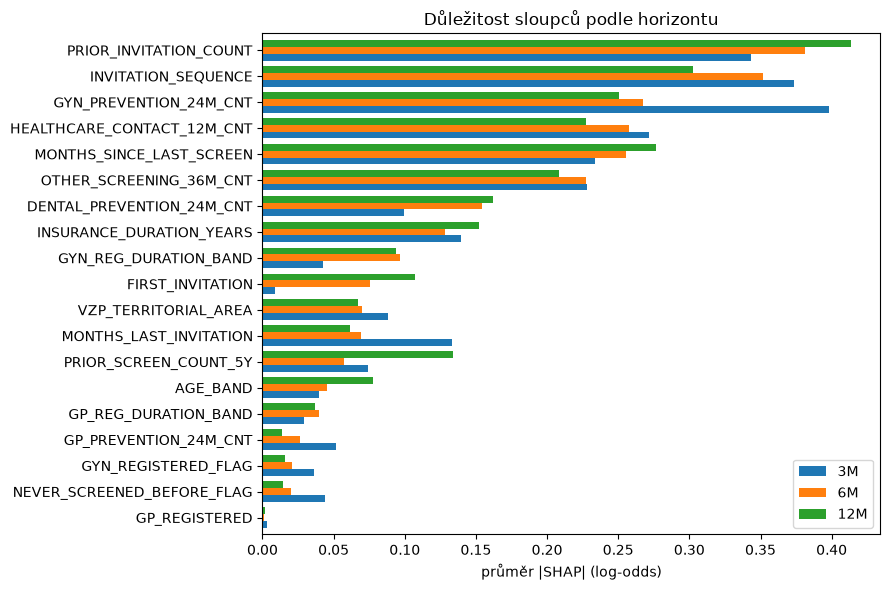

,3M,6M,12M
PRIOR_INVITATION_COUNT,0.343,0.381,0.413
INVITATION_SEQUENCE,0.374,0.352,0.303
GYN_PREVENTION_24M_CNT,0.398,0.267,0.250
HEALTHCARE_CONTACT_12M_CNT,0.272,0.258,0.227
MONTHS_SINCE_LAST_SCREEN,0.233,0.255,0.277
OTHER_SCREENING_36M_CNT,0.228,0.227,0.208
DENTAL_PREVENTION_24M_CNT,0.100,0.155,0.162
INSURANCE_DURATION_YEARS,0.140,0.128,0.152
GYN_REG_DURATION_BAND,0.043,0.097,0.094
FIRST_INVITATION,0.009,0.075,0.107


In [4]:
vz = test.sample(20_000, random_state=0)
SHAP, imp = {}, {}
for y, m in MODELS.items():
    sv = m.get_feature_importance(Pool(vz[FEATURES], cat_features=CAT), type="ShapValues")[:, :-1]
    SHAP[y] = sv
    imp[y.split("_")[1]] = np.abs(sv).mean(axis=0)
IMP = pd.DataFrame(imp, index=FEATURES).sort_values("6M", ascending=False)
IMP.to_csv(OUT / "shap_dulezitost.csv")

fig, ax = plt.subplots(figsize=(9, 6))
IMP.iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.set_xlabel("průměr |SHAP| (log-odds)"); ax.set_title("Důležitost sloupců podle horizontu")
plt.tight_layout(); plt.savefig(OUT / "shap_dulezitost.png", dpi=120); plt.show()
IMP.round(3)

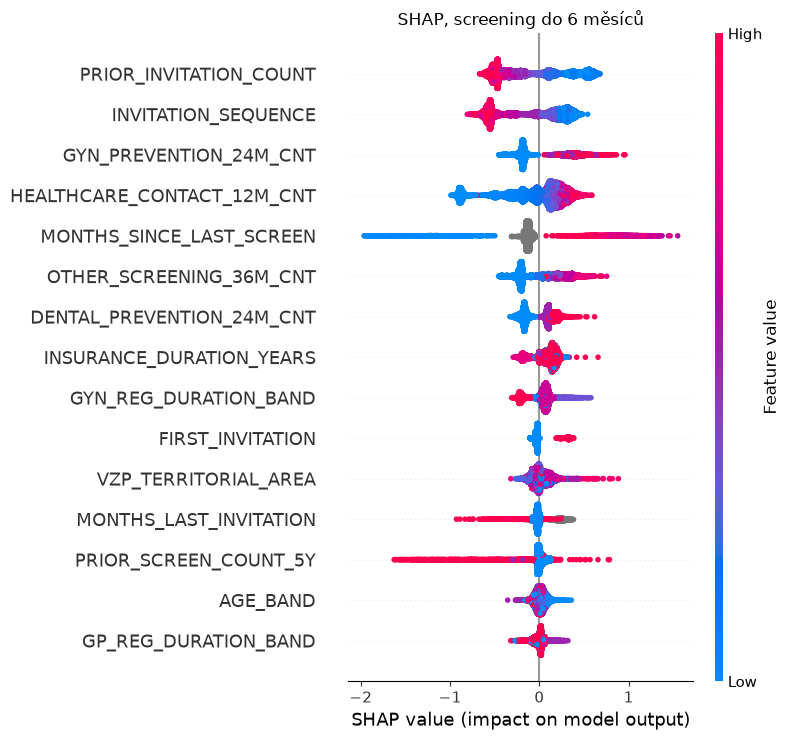

In [5]:
# beeswarm pro 6 měsíců; kategorie převedené na pořadová čísla jen kvůli barvě bodů
Xv = vz[FEATURES].copy()
for c in CAT:
    Xv[c] = Xv[c].astype("category").cat.codes
shap.summary_plot(SHAP["SCREENING_6M_FLAG"], Xv, max_display=15, show=False)
plt.title("SHAP, screening do 6 měsíců"); plt.tight_layout()
plt.savefig(OUT / "shap_beeswarm_6m.png", dpi=120); plt.show()

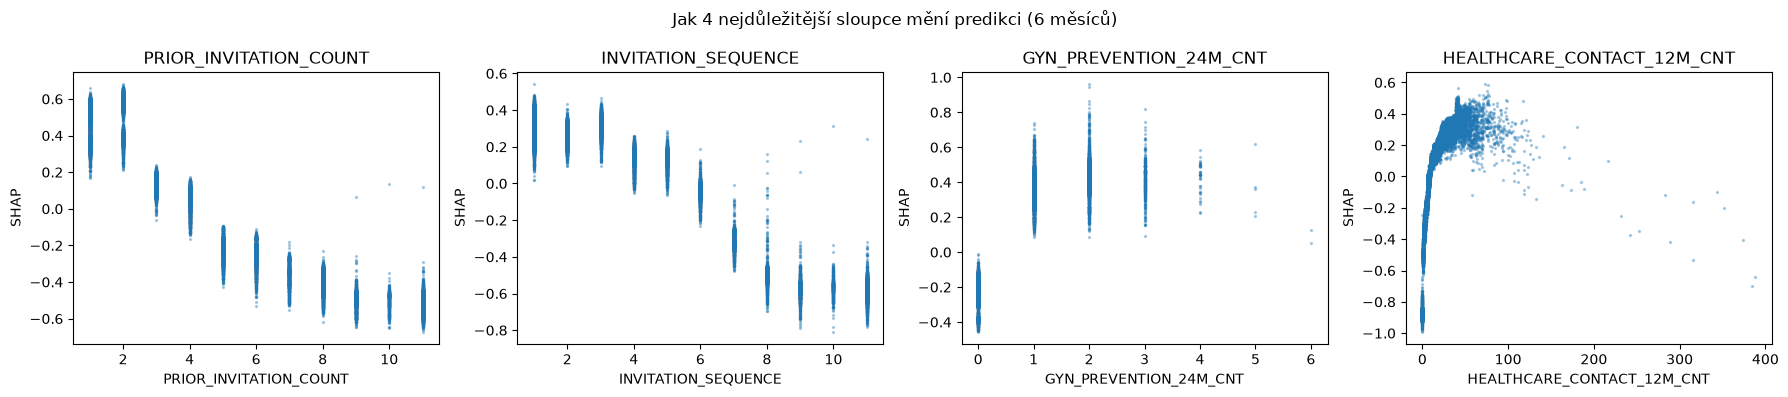

In [6]:
top = IMP.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, top):
    j = FEATURES.index(c)
    if c in CAT:
        s = pd.DataFrame({"hodnota": vz[c].values, "shap": SHAP["SCREENING_6M_FLAG"][:, j]})
        s.groupby("hodnota").shap.mean().sort_values().plot.barh(ax=ax)
        ax.set_xlabel("průměrný SHAP")
    else:
        ax.scatter(vz[c], SHAP["SCREENING_6M_FLAG"][:, j], s=2, alpha=0.3)
        ax.set_xlabel(c); ax.set_ylabel("SHAP")
    ax.set_title(c)
plt.suptitle("Jak 4 nejdůležitější sloupce mění predikci (6 měsíců)"); plt.tight_layout()
plt.savefig(OUT / "shap_zavislosti_6m.png", dpi=120); plt.show()

## 4 · Kde model funguje hůř: výkon po věkových pásmech (6 měsíců, test 2024)

In [7]:
t = d.loc[test.index]
POD = (t.groupby("AGE_BAND")
        .apply(lambda g: pd.Series({"pozvánek": len(g), "podíl účasti": g.SCREENING_6M_FLAG.mean(),
                                    "AUROC": roc_auc_score(g.SCREENING_6M_FLAG, g.p_SCREENING_6M_FLAG)}),
               include_groups=False))
POD.round(3)

,pozvánek,podíl účasti,AUROC
AGE_BAND,,,
40-44,9361.0,0.404,0.699
45-49,71128.0,0.213,0.796
50-54,42529.0,0.086,0.781
55-59,40867.0,0.074,0.811
60-64,40983.0,0.070,0.812
65-69,44662.0,0.065,0.815
70-74,6936.0,0.063,0.809


## 5 · Řádky jsou pozvánky, ne ženy

Jedna žena má v datech až 5 pozvánek. Ženy pozvané pětkrát (zvané každý rok a většinou
nepřicházející) mají v učení i v SHAP pětinásobnou váhu. Pro každý horizont proto:

* **účast na pozvánku vs. na ženu** (přišla aspoň po jedné pozvánce),
* **AUROC zvlášť pro ženy, které model viděl při učení, a pro nové** (celkové AUROC může nafukovat
  rozdíl mezi těmito skupinami),
* **95% interval AUROC s převzorkováním žen**, ne řádků,
* **model s váhou 1/počet pozvánek ženy**, aby každá žena vážila stejně, a srovnání průměrného |SHAP| i pořadí,
* **překryv oken štítků**: dvojice pozvánek téže ženy, mezi nimiž je méně než délka okna.

In [8]:
rng = np.random.default_rng(0)
seen = test.PERSON_ID.isin(set(train.PERSON_ID))
w_tr = 1 / train.groupby("PERSON_ID").PERSON_ID.transform("size")
skup = test.groupby("PERSON_ID").indices
ids = np.array(list(skup))
dd = d.sort_values(["PERSON_ID", "INVITATION_DATE"])
mezera = (dd.groupby("PERSON_ID").INVITATION_DATE.shift(-1) - dd.INVITATION_DATE).dt.days
okno = {"3M": 90, "6M": 180, "12M": 365}
print("pozvánek na ženu:", d.groupby("PERSON_ID").size().value_counts().sort_index().to_dict())

rows, IMPW = [], {}
for y in LABELS:
    h = y.split("_")[1]
    p = d.loc[test.index, f"p_{y}"].values
    yt = test[y].values
    boot = []
    for _ in range(200):
        ix = np.concatenate([skup[k] for k in rng.choice(ids, len(ids))])
        boot.append(roc_auc_score(yt[ix], p[ix]))
    mw = CatBoostClassifier(iterations=1500, learning_rate=0.1, depth=6, eval_metric="AUC",
                            od_type="Iter", od_wait=100, thread_count=-1, random_seed=0, verbose=0)
    mw.fit(Pool(train[FEATURES], train[y], cat_features=CAT, weight=w_tr),
           eval_set=Pool(valid[FEATURES], valid[y], cat_features=CAT))
    pw = mw.predict_proba(Pool(test[FEATURES], cat_features=CAT))[:, 1]
    svw = mw.get_feature_importance(Pool(vz[FEATURES], cat_features=CAT), type="ShapValues")[:, :-1]
    IMPW[h] = pd.Series(np.abs(svw).mean(0), index=FEATURES)
    nasl = dd.groupby("PERSON_ID")[y].shift(-1)
    rows.append({"horizont": h,
                 "účast na pozvánku": d[y].mean(), "účast na ženu (aspoň jednou)": d.groupby("PERSON_ID")[y].max().mean(),
                 "AUROC vše": roc_auc_score(yt, p), "AUROC 95% CI (ženy)": f"{np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f}",
                 "AUROC známé ženy": roc_auc_score(yt[seen], p[seen]), "AUROC nové ženy": roc_auc_score(yt[~seen], p[~seen]),
                 "účast známé": yt[seen].mean(), "účast nové": yt[~seen].mean(),
                 "AUROC model vážený na ženu": roc_auc_score(yt, pw),
                 "dvojice s překryvem okna, obě A": int(((mezera < okno[h]) & (dd[y] == 1) & (nasl == 1)).sum())})
OPAK = pd.DataFrame(rows).set_index("horizont")
OPAK.to_csv(OUT / "opakovane_pozvanky.csv")
print(f"testovacích pozvánek od žen, které model viděl při učení: {seen.mean():.0%}")
display(OPAK.T)
# průměrné |SHAP| (log-odds) modelu na pozvánku a modelu váženého na ženu, k tomu pořadí
SHW = pd.concat({h: pd.DataFrame({"na pozvánku": IMP[h], "na ženu": IMPW[h]}) for h in IMPW}, axis=1)
SHW = SHW.loc[SHW[("6M", "na ženu")].sort_values(ascending=False).index]
SHW.round(3).to_csv(OUT / "shap_pozvanka_vs_zena.csv")
POR = SHW.rank(ascending=False).astype(int)
POR.to_csv(OUT / "shap_poradi_pozvanka_vs_zena.csv")
display(SHW.round(3))
POR

pozvánek na ženu: {1: 190970, 2: 95778, 3: 54097, 4: 38671, 5: 129011}


testovacích pozvánek od žen, které model viděl při učení: 77%


horizont,3M,6M,12M
účast na pozvánku,0.071227,0.12541,0.193027
účast na ženu (aspoň jednou),0.187603,0.329141,0.496162
AUROC vše,0.834646,0.835724,0.836567
AUROC 95% CI (ženy),0.832–0.837,0.834–0.838,0.835–0.838
AUROC známé ženy,0.793911,0.781562,0.77052
AUROC nové ženy,0.734456,0.743718,0.773825
účast známé,0.037443,0.067821,0.113282
účast nové,0.182442,0.311988,0.454973
AUROC model vážený na ženu,0.831549,0.832419,0.834386
"dvojice s překryvem okna, obě A",0,0,3858


3M                  6M                 12M        
                           na pozvánku na ženu na pozvánku na ženu na pozvánku na ženu
PRIOR_INVITATION_COUNT           0.343   0.550       0.381   0.516       0.413   0.561
GYN_PREVENTION_24M_CNT           0.398   0.365       0.267   0.275       0.250   0.271
MONTHS_SINCE_LAST_SCREEN         0.233   0.253       0.255   0.274       0.277   0.314
INSURANCE_DURATION_YEARS         0.140   0.198       0.128   0.268       0.152   0.223
HEALTHCARE_CONTACT_12M_CNT       0.272   0.244       0.258   0.237       0.227   0.254
OTHER_SCREENING_36M_CNT          0.228   0.245       0.227   0.234       0.208   0.197
INVITATION_SEQUENCE              0.374   0.233       0.352   0.224       0.303   0.272
DENTAL_PREVENTION_24M_CNT        0.100   0.117       0.155   0.164       0.162   0.161
PRIOR_SCREEN_COUNT_5Y            0.074   0.093       0.058   0.127       0.134   0.128
MONTHS_LAST_INVITATION           0.133   0.083       0.069   0.078       0.061   0.073
GYN_REG_DURATION_BAND            0.043   0.046       0.097   0.072       0.094   0.076
AGE_BAND                         0.040   0.094       0.045   0.061       0.078   0.107
VZP_TERRITORIAL_AREA             0.088   0.085       0.070   0.052       0.067   0.081
FIRST_INVITATION                 0.009   0.064       0.075   0.037       0.107   0.021
NEVER_SCREENED_BEFORE_FLAG       0.044   0.013       0.020   0.022       0.014   0.065
GP_PREVENTION_24M_CNT            0.051   0.057       0.026   0.021       0.014   0.015
GP_REG_DURATION_BAND             0.030   0.027       0.040   0.018       0.037   0.047
GYN_REGISTERED_FLAG              0.036   0.032       0.021   0.014       0.016   0.015
GP_REGISTERED                    0.003   0.003       0.001   0.000       0.002   0.000

3M                  6M                 12M        
                           na pozvánku na ženu na pozvánku na ženu na pozvánku na ženu
PRIOR_INVITATION_COUNT               3       1           1       1           1       1
GYN_PREVENTION_24M_CNT               1       2           3       2           4       4
MONTHS_SINCE_LAST_SCREEN             5       3           5       3           3       2
INSURANCE_DURATION_YEARS             7       7           8       4           8       6
HEALTHCARE_CONTACT_12M_CNT           4       5           4       5           5       5
OTHER_SCREENING_36M_CNT              6       4           6       6           6       7
INVITATION_SEQUENCE                  2       6           2       7           2       3
DENTAL_PREVENTION_24M_CNT            9       8           7       8           7       8
PRIOR_SCREEN_COUNT_5Y               11      10          13       9           9       9
MONTHS_LAST_INVITATION               8      12          12      10          14      13
GYN_REG_DURATION_BAND               14      15           9      11          11      12
AGE_BAND                            15       9          14      12          12      10
VZP_TERRITORIAL_AREA                10      11          11      13          13      11
FIRST_INVITATION                    18      13          10      14          10      16
NEVER_SCREENED_BEFORE_FLAG          13      18          18      15          17      14
GP_PREVENTION_24M_CNT               12      14          16      16          18      17
GP_REG_DURATION_BAND                17      17          15      17          15      15
GYN_REGISTERED_FLAG                 16      16          17      18          16      18
GP_REGISTERED                       19      19          19      19          19      19

**Jak to číst.** Celkové AUROC kolem 0,84 je částečně dané tím, že model odliší nově zvané ženy
(chodí často) od opakovaně zvaných (chodí málo); uvnitř obou skupin je AUROC nižší (0,73–0,79).
Pro VZP jsou proto poctivější čísla zvlášť pro známé a nové ženy. Interval přes převzorkování žen
je úzký: při půl milionu žen opakování nejistotu skoro nezvětšuje. Pořadí důležitosti je při váze
„každá žena jednou“ podobné; mění se hlavně pořadové číslo pozvánky u 3 a 6 měsíců (jeho váhu
dávaly ženy zvané pětkrát). Okna 3 a 6 měsíců se nepřekrývají (pozvánky jsou od sebe aspoň
8 měsíců), u 12 měsíců může jedna mamografie započítat úspěch dvou pozvánek (asi 1,5 % kladných
štítků).

## 6 · Jeden model pro čas do mamografie (diskrétní přežití)

Tři štítky jsou vnořené (3M ⊂ 6M ⊂ 12M, v datech bez výjimky), tři samostatné modely to ale
nevědí: předpověď do 3 měsíců může vyjít vyšší než do 6. Diskrétní model přežití odhaduje
**hazard** h_k, tj. šanci, že žena přijde v intervalu 0–3, 3–6 nebo 6–12 měsíců, pokud nepřišla
dřív. Pozvánka má jeden řádek za každý interval, ve kterém byla „v riziku“; číslo intervalu je
prediktor, takže stromy dovolí, aby se vliv sloupců v čase měnil. Pravděpodobnost účasti do konce
intervalu k je 1 − ∏(1 − h_j), a je tedy z konstrukce rostoucí. Early stopping podle log-loss.

In [9]:
INT = ["0–3", "3–6", "6–12"]

def roztahni(df):
    """Jeden řádek za interval v riziku; y = 1 v intervalu, kdy žena přišla."""
    ud = 4 - df[LABELS].sum(axis=1)  # 1 = do 3 měsíců, 2 = 3–6, 3 = 6–12, 4 = do 12 měsíců nepřišla
    parts = []
    for k in (1, 2, 3):
        r = df.loc[ud >= k, FEATURES].assign(INTERVAL=k)
        r["y"] = (ud[ud >= k] == k).astype(int)
        parts.append(r)
    return pd.concat(parts)

FS = FEATURES + ["INTERVAL"]
pp_tr, pp_va, pp_te = roztahni(train), roztahni(valid), roztahni(test)
print(f"řádků osoba-interval: učení {len(pp_tr):,} · ladění {len(pp_va):,} · test {len(pp_te):,}")
MS = CatBoostClassifier(iterations=3000, learning_rate=0.1, depth=6, eval_metric="Logloss",
                        od_type="Iter", od_wait=100, thread_count=-1, random_seed=0, verbose=0)
MS.fit(Pool(pp_tr[FS], pp_tr.y, cat_features=CAT), eval_set=Pool(pp_va[FS], pp_va.y, cat_features=CAT))

H = np.column_stack([MS.predict_proba(Pool(test[FEATURES].assign(INTERVAL=k), cat_features=CAT))[:, 1]
                     for k in (1, 2, 3)])
F = 1 - np.cumprod(1 - H, axis=1)  # sloupce: do 3, 6, 12 měsíců
P = d.loc[test.index, [f"p_{y}" for y in LABELS]].values
rows = []
for j, y in enumerate(LABELS):
    yt = test[y].values
    rows.append({"horizont": y.split("_")[1], "podíl účasti": yt.mean(),
                 "průměr predikce 3 modely": P[:, j].mean(), "průměr predikce přežití": F[:, j].mean(),
                 "AUROC 3 modely": roc_auc_score(yt, P[:, j]), "AUROC přežití": roc_auc_score(yt, F[:, j]),
                 "PR-AUC 3 modely": average_precision_score(yt, P[:, j]),
                 "PR-AUC přežití": average_precision_score(yt, F[:, j])})
PREZ = pd.DataFrame(rows).set_index("horizont")
PREZ.to_csv(OUT / "preziti_vs_3_modely.csv")
print(f"iterací: {MS.get_best_iteration()}")
print(f"3 samostatné modely: nekonzistentní pořadí horizontů u {((P[:, 0] > P[:, 1]) | (P[:, 1] > P[:, 2])).mean():.1%} "
      "testovacích pozvánek (model přežití 0 % z konstrukce)")
hz = pd.DataFrame({"pozorovaný hazard": pp_te.groupby("INTERVAL").y.mean(),
                   "predikovaný hazard": pd.Series(MS.predict_proba(Pool(pp_te[FS], cat_features=CAT))[:, 1],
                                                   index=pp_te.index).groupby(pp_te.INTERVAL.values).mean().values,
                   "v riziku": pp_te.groupby("INTERVAL").size()})
hz.index = INT
display(hz.round(3))
PREZ.round(3)

řádků osoba-interval: učení 2,700,854 · ladění 349,043 · test 719,381


iterací: 729
3 samostatné modely: nekonzistentní pořadí horizontů u 0.8% testovacích pozvánek (model přežití 0 % z konstrukce)


,pozorovaný hazard,predikovaný hazard,v riziku
0–3,0.071,0.068,256466
3–6,0.057,0.054,238286
6–12,0.078,0.074,224629


,podíl účasti,průměr predikce 3 modely,průměr predikce přežití,AUROC 3 modely,AUROC přežití,PR-AUC 3 modely,PR-AUC přežití
horizont,,,,,,,
3M,0.071,0.068,0.068,0.835,0.835,0.285,0.286
6M,0.124,0.118,0.119,0.836,0.836,0.431,0.431
12M,0.192,0.184,0.184,0.837,0.836,0.578,0.577


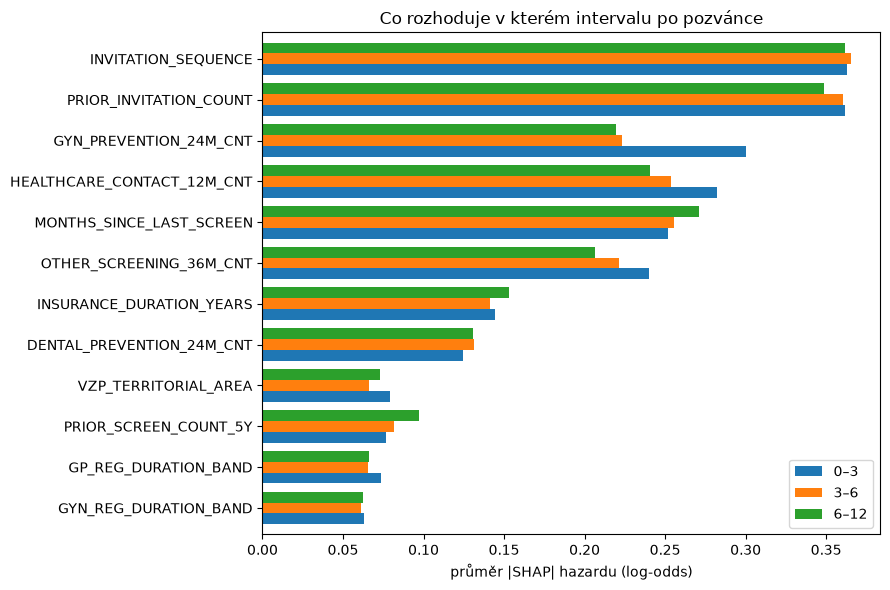

,0–3,3–6,6–12
INVITATION_SEQUENCE,0.363,0.365,0.362
PRIOR_INVITATION_COUNT,0.362,0.360,0.349
GYN_PREVENTION_24M_CNT,0.300,0.223,0.219
HEALTHCARE_CONTACT_12M_CNT,0.282,0.254,0.241
MONTHS_SINCE_LAST_SCREEN,0.252,0.256,0.271
OTHER_SCREENING_36M_CNT,0.240,0.221,0.207
INSURANCE_DURATION_YEARS,0.144,0.141,0.153
DENTAL_PREVENTION_24M_CNT,0.125,0.131,0.130
VZP_TERRITORIAL_AREA,0.079,0.066,0.073
PRIOR_SCREEN_COUNT_5Y,0.077,0.081,0.097


In [10]:
# průměrné |SHAP| hazardu po intervalech: stejných 20 000 testovacích pozvánek, interval nastavený na k
SV = {}
for k, nm in zip((1, 2, 3), INT):
    sv = MS.get_feature_importance(Pool(vz[FEATURES].assign(INTERVAL=k), cat_features=CAT), type="ShapValues")[:, :-1]
    SV[nm] = np.abs(sv[:, :len(FEATURES)]).mean(0)
HIMP = pd.DataFrame(SV, index=FEATURES).sort_values("0–3", ascending=False)
HIMP.round(3).to_csv(OUT / "preziti_shap_po_intervalech.csv")

fig, ax = plt.subplots(figsize=(9, 6))
HIMP.iloc[:12][::-1].plot.barh(ax=ax, width=0.8)
ax.set_xlabel("průměr |SHAP| hazardu (log-odds)"); ax.set_title("Co rozhoduje v kterém intervalu po pozvánce")
plt.tight_layout(); plt.savefig(OUT / "preziti_shap_po_intervalech.png", dpi=120); plt.show()
HIMP.round(3)

**Jak to číst.** Jeden model přežití rozlišuje stejně dobře jako tři samostatné modely (AUROC
0,835–0,837, PR-AUC prakticky shodné) a je stejně kalibrovaný; oba mírně podhodnocují rok 2024
(do 12 měsíců 18,4 % predikce proti 19,2 % skutečnosti). Výhoda je v konzistenci: tři modely
seřadí horizonty obráceně u 0,8 % pozvánek, model přežití nikdy, a dává i průběh v čase. Hazard je
nejvyšší hned po pozvánce (7,1 % za 0–3 měsíce, 5,7 % za 3–6), interval 6–12 měsíců má 7,8 % za
šest měsíců, tedy zhruba polovinu na čtvrtletí. Vliv sloupců se v čase mění málo; nejvíc
preventivní gynekologie (průměr |SHAP| 0,30 v prvních 3 měsících, 0,22 později) a kontakty se
zdravotnictvím, které také působí hlavně brzy. Měsíce od posledního screeningu naopak mírně sílí
s časem. Pro VZP stačí jeden model a z něj odečíst libovolný horizont.

## Poznámky

* **Cílová proměnná není jen screening.** Kódy štítků (89178, 89223, 89225, 89314, 89510, 89814)
  zahrnují i doplňující snímky, ultrazvuk a biopsii; „účast“ tak zahrnuje i dovyšetření a historie
  screeningů může jednu epizodu započítat vícekrát.
* **`VZP_TERRITORIAL_AREA` je územní pracoviště VZP, ne okres**, okresní ukazatele (dostupnost,
  lhůty, socioekonomika) na něj zatím napojit nejde. Věk 75+ v datech není.
* **SHAP popisuje model, ne příčiny.** Vysoký příspěvek historie screeningu neznamená, že ji
  intervence změní; o účinku intervencí rozhodne experiment (`docs/interventions.md`).
* Výsledky se týkají žen, které dostaly adresnou pozvánku (většinou dosud nescreenovaných), ne celé
  populace žen 45+.